In [1]:
import sys
import matplotlib.pyplot as plt

src_path = "/home/valen/BE_DataSciences/src"

if src_path not in sys.path:
    sys.path.append(src_path)

import analyse_donnees as AN

In [2]:
features_train = AN.read_ds("train")
features_test = AN.read_ds("test")
print(features_train.shape)

features_train[["util","navigateur"]].describe()


(3279, 14470)


,util,navigateur
count,3279,3279
unique,247,4
top,skm,Firefox
freq,75,1466


top: most frequent value in the column
freq: Frequency of the most common value

In [3]:
# Utilisateur utilise toujours le même navigateur
print(f"Nombre maximum de navigateurs utilisés par un utilisateur: {AN.browsers_per_player(features_train)}")
features_train['navigateur'].unique()


Nombre maximum de navigateurs utilisés par un utilisateur: 1


<StringArray>
['Firefox', 'Google Chrome', 'Microsoft Edge', 'Opera']
Length: 4, dtype: str

  util  min_t   max_t    moyenne_t        std_t
0  aho  115.0  1985.0   742.000000   628.455779
1  ajo  125.0  2095.0  1269.230769   609.866263
2  akx   95.0   965.0   413.214286   288.381472
3  ald   40.0  3620.0  1074.666667  1112.091766
4  ats   80.0  3135.0   800.416667   828.200290
Plus longue session: 11790.0


Text(0, 0.5, 'Fréquence')

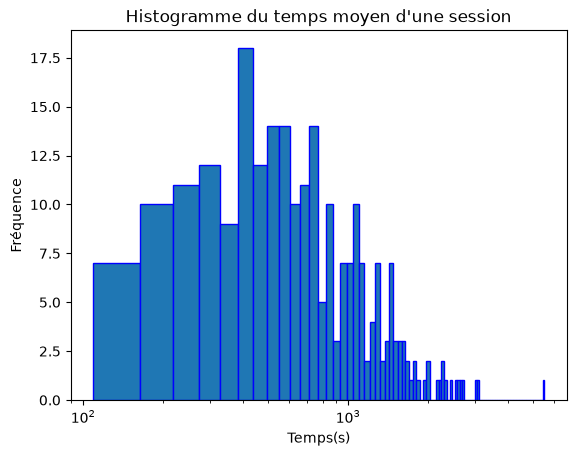

In [10]:
updated_df = AN.temps_par_session(features_train)
print(updated_df.head())

max_val = updated_df["max_t"].max()
bin_width = 120 # 60: regroupe par minute, 300 regroupe par 5 min
print(f"Plus longue session: {max_val}")
ax = updated_df["moyenne_t"].plot(kind='hist', logx=True,bins=int(max_val/bin_width),edgecolor="blue")
ax.set_title("Histogramme du temps moyen d'une session")
ax.set_xlabel("Temps(s)")
ax.set_ylabel("Fréquence")
#updated_df["moyenne_t"].hist(bins="fd",edgecolor="blue")

             min_t         max_t    moyenne_t        std_t    rapidite
count   247.000000    247.000000   247.000000   247.000000  247.000000
mean    123.178138   2439.392713   858.725094   786.564884    4.720679
std     204.941794   1985.056274   649.403171   729.170713    1.003587
min       5.000000    185.000000   109.000000    43.358967    2.418332
25%      65.000000   1145.000000   416.544444   336.545726    4.136696
50%      95.000000   1910.000000   700.000000   567.833183    4.652462
75%     130.000000   3012.500000  1098.831169   977.640451    5.126566
max    3135.000000  11790.000000  5487.000000  4124.756444    9.715122
    util  min_t   max_t  moyenne_t        std_t  rapidite
5    avt   15.0  1995.0   937.0000   661.407590  8.942581
8    azx   10.0   895.0   254.0000   249.675345  9.093013
158  qof   55.0  1535.0   704.6875   462.530967  8.389314
165  sbz   75.0  6780.0  2639.0000  2809.956405  9.715122


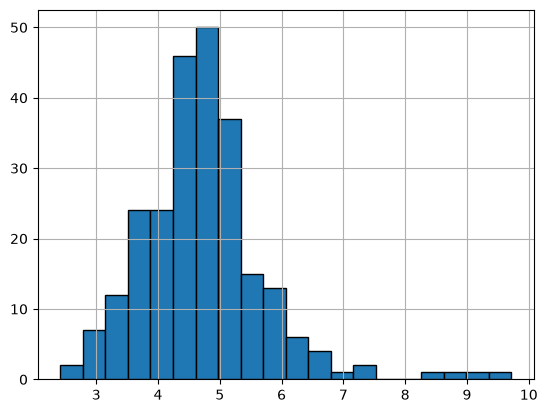

In [5]:
df = AN.rapidite_util(features_train,updated_df)
print(df.describe())
df["rapidite"].hist(bins=20, edgecolor="black")
print(df[df["rapidite"]>8])

In [6]:
updated_df = AN.transform_navig(features_train,updated_df)
updated_df.head()

,util,min_t,max_t,moyenne_t,std_t,rapidite,navigateur
0,aho,115.0,1985.0,742.000000,628.455779,4.891508,1
1,ajo,125.0,2095.0,1269.230769,609.866263,5.237337,0
2,akx,95.0,965.0,413.214286,288.381472,5.251325,1
3,ald,40.0,3620.0,1074.666667,1112.091766,4.921765,1
4,ats,80.0,3135.0,800.416667,828.200290,4.696244,0


In [7]:
updated_df = AN.stat_actions(features_train,updated_df)
updated_df.head()

OK1
OK2
OK3
OK4
OK5
OK2
OK3
OK4
OK5
OK2
OK3
OK4
OK5
OK2
OK3
OK4
OK5


,util,min_t,max_t,moyenne_t,std_t,rapidite,navigateur,min_modif,max_modif,mean_modif,...,mean_fiche,std_fiche,min_ecran,max_ecran,mean_ecran,std_ecran,min_changement_ecran,max_changement_ecran,mean_changement_ecran,std_changement_ecran
0,aho,115.0,1985.0,742.000000,628.455779,4.891508,1,9,406,81.500000,...,58.400000,56.228107,19,212,90.200000,72.651069,7,120,46.300000,38.841702
1,ajo,125.0,2095.0,1269.230769,609.866263,5.237337,0,15,804,305.769231,...,24.538462,25.078594,20,309,174.153846,86.272674,9,158,83.000000,46.173586
2,akx,95.0,965.0,413.214286,288.381472,5.251325,1,0,409,152.071429,...,19.214286,31.657247,3,84,28.571429,23.190563,1,44,14.214286,13.250130
3,ald,40.0,3620.0,1074.666667,1112.091766,4.921765,1,0,471,125.666667,...,132.600000,209.383380,6,374,117.000000,118.628472,2,120,34.666667,38.066984
4,ats,80.0,3135.0,800.416667,828.200290,4.696244,0,0,245,80.500000,...,85.166667,93.180015,13,369,92.500000,96.035505,6,236,59.583333,62.171988


array([[<Axes: title={'center': 'mean_changement_ecran'}>,
        <Axes: title={'center': 'mean_ecran'}>],
       [<Axes: title={'center': 'mean_fiche'}>,
        <Axes: title={'center': 'mean_modif'}>]], dtype=object)

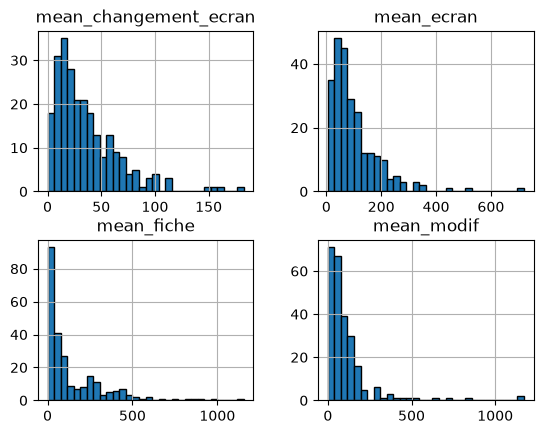

In [9]:

updated_df[["mean_changement_ecran","mean_ecran","mean_fiche","mean_modif"]].hist(bins=30, edgecolor="black")